![Banner](../images/09_13_banner_rs_capstones.png)


# Tree Inventory, Biomass and Carbon from Airborne Lidar

Produce a forest inventory for a 2.4 km² landscape from airborne lidar: terrain, canopy
height, individual trees with heights and crown sizes, above-ground biomass and carbon per tree and
per hectare, an area-based biomass model with prediction intervals, and a summary for a carbon or
forest-management report.


## Overview

Produce a forest inventory for a 2.4 km² landscape from airborne lidar: terrain, canopy
height, individual trees with heights and crown sizes, above-ground biomass and carbon per tree and
per hectare, an area-based biomass model with prediction intervals, and a summary for a carbon or
forest-management report.

**Skills combined:** point cloud handling and units (Module 17), ground filtering, CHM, crown
segmentation and area-based metrics (Module 18), regression with spatial CV and conformal
prediction (Module 22).

**Data (real):** classified airborne lidar of Madison, Mississippi (4.1 M points).

**Assumption to state in any report:** biomass comes from a published *crown-based* allometry
(Jucker et al. 2017, angiosperm equation), not from field plots, so absolute values carry the
allometry's uncertainty (≈ 20-30 % per tree). Field calibration plots would replace it in practice.

### Workflow

1. Prepare the point cloud
2. Terrain and canopy height
3. Individual-tree inventory
4. Tree biomass and carbon
5. Area-based biomass model with prediction intervals
6. Inventory report


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pyproj import Transformer

import geolattice.rsense as rs
plt.rcParams.update({"figure.dpi": 110})

In [2]:
from pathlib import Path
import urllib.request

DATA = Path("../../../../Data/08_remote_sensing/08_11_Capstones")
DATA.mkdir(exist_ok=True)
GH = "https://github.com/opengeos/datasets/releases/download"
RAW = "https://raw.githubusercontent.com"
EOP = f"{RAW}/sentinel-hub/eo-learn/develop/example_data/TestEOPatch"
DF = f"{RAW}/weecology/DeepForest/main/src/deepforest/data"
URLS = {
    "landsat_las_vegas.tif": f"{GH}/raster/landsat_las_vegas.tif",
    **{f"pucallpa_{y}.tif": f"{RAW}/opengeos/data/main/landsat/{y}.tif" for y in range(1985, 2021, 5)},
    "landsat.tif": f"{GH}/raster/landsat.tif", "dem_90m.tif": f"{GH}/book/dem_90m.tif",
    "s2_bands.npy": f"{EOP}/data/BANDS-S2-L1C.npy", "s2_clp.npy": f"{EOP}/data/CLP.npy",
    "s2_lulc.npy": f"{EOP}/mask_timeless/LULC.npy", "s2_timestamps.json": f"{EOP}/timestamps.json",
    "s2_bbox.geojson": f"{EOP}/bbox.geojson",
    **{f"australia.{e}": f"{DF}/australia.{e}" for e in ("tif", "shp", "shx", "dbf", "prj")},
    "madison.copc.laz": f"{GH}/lidar/madison.copc.laz",
    "ecostress_lst.tif": f"{GH}/raster/ECOv002_L2T_LSTE_26860_001_10SGD_20230401T203733_0710_01_LST.tif",
}
NLCD_URL = f"{GH}/raster/nlcd_2021_land_cover_90m.tif"

def fetch(name):
    """Download a tutorial dataset once and return its local path."""
    path = DATA / name
    if not path.exists():
        print(f"Downloading {name} ...")
        urllib.request.urlretrieve(URLS[name], path)
    return path

def nlcd_for(template, name="nlcd_window"):
    """NLCD 2021 on the grid of `template` (windowed read of the CONUS COG, cached)."""
    from rasterio.enums import Resampling
    cache = DATA / f"{name}.tif"
    if not cache.exists():
        import rasterio, rioxarray
        from rasterio.warp import transform_bounds
        with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
            src = rioxarray.open_rasterio("/vsicurl/" + NLCD_URL)
            b = transform_bounds(template.rio.crs, src.rio.crs, *template.rio.bounds())
            rs.write(src.rio.clip_box(*b).squeeze("band", drop=True).load(), cache, cog=False)
    win = rs.read(cache, masked=False).squeeze("band", drop=True).rio.write_nodata(0)
    return win.rio.reproject_match(template, resampling=Resampling.nearest, nodata=0).astype("int16")

def load_s2():
    """Real Sentinel-2 L1C time series (eo-learn TestEOPatch) as an xarray Dataset."""
    import json
    b = np.load(fetch("s2_bands.npy")); clp = np.load(fetch("s2_clp.npy"))[..., 0]
    lulc = np.load(fetch("s2_lulc.npy"))[..., 0]
    t = pd.to_datetime(json.load(open(fetch("s2_timestamps.json"))))
    bb = json.load(open(fetch("s2_bbox.geojson")))["coordinates"][0]
    names = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B10", "B11", "B12"]
    x = min(p[0] for p in bb) + 10 * (np.arange(b.shape[2]) + 0.5)
    y = max(p[1] for p in bb) - 10 * (np.arange(b.shape[1]) + 0.5)
    ds = xr.Dataset({n: (("time", "y", "x"), b[..., i]) for i, n in enumerate(names)},
                    coords={"time": t, "y": y, "x": x}).rio.write_crs(32633)
    ds["cloud_prob"] = (("time", "y", "x"), clp)
    ds.attrs["pyrsense:sensor"] = "sentinel2"
    lc = xr.DataArray(lulc, dims=("y", "x"), coords={"y": y, "x": x}).rio.write_crs(32633)
    return ds, lc

## Prepare the point cloud


In [3]:
raw = rs.lidar.read_las(fetch("madison.copc.laz"))
lon, lat = Transformer.from_crs(raw.crs, 4326, always_xy=True).transform(np.mean(raw.bbox[::2]), np.mean(raw.bbox[1::2]))
utm = rs.core.utm_epsg(lon, lat)
x, y = Transformer.from_crs(raw.crs, utm, always_xy=True).transform(raw.x, raw.y)
pc = rs.PointCloud(np.asarray(x), np.asarray(y), np.asarray(raw.z) * 0.3048006096, dict(raw.attrs), utm).drop_noise()
area_ha = (pc.bbox[2] - pc.bbox[0]) * (pc.bbox[3] - pc.bbox[1]) / 1e4
print(f"{len(pc):,} points in EPSG:{utm}; area {area_ha:.0f} ha; density {len(pc) / (area_ha * 1e4):.2f} pts/m²")

4,067,917 points in EPSG:32615; area 244 ha; density 1.67 pts/m²


## Terrain and canopy height

The provider's ground classification is checked against SMRF before use; the CHM is built at 1 m
with pit filling.


SMRF vs provider ground labels: 94.7% agreement


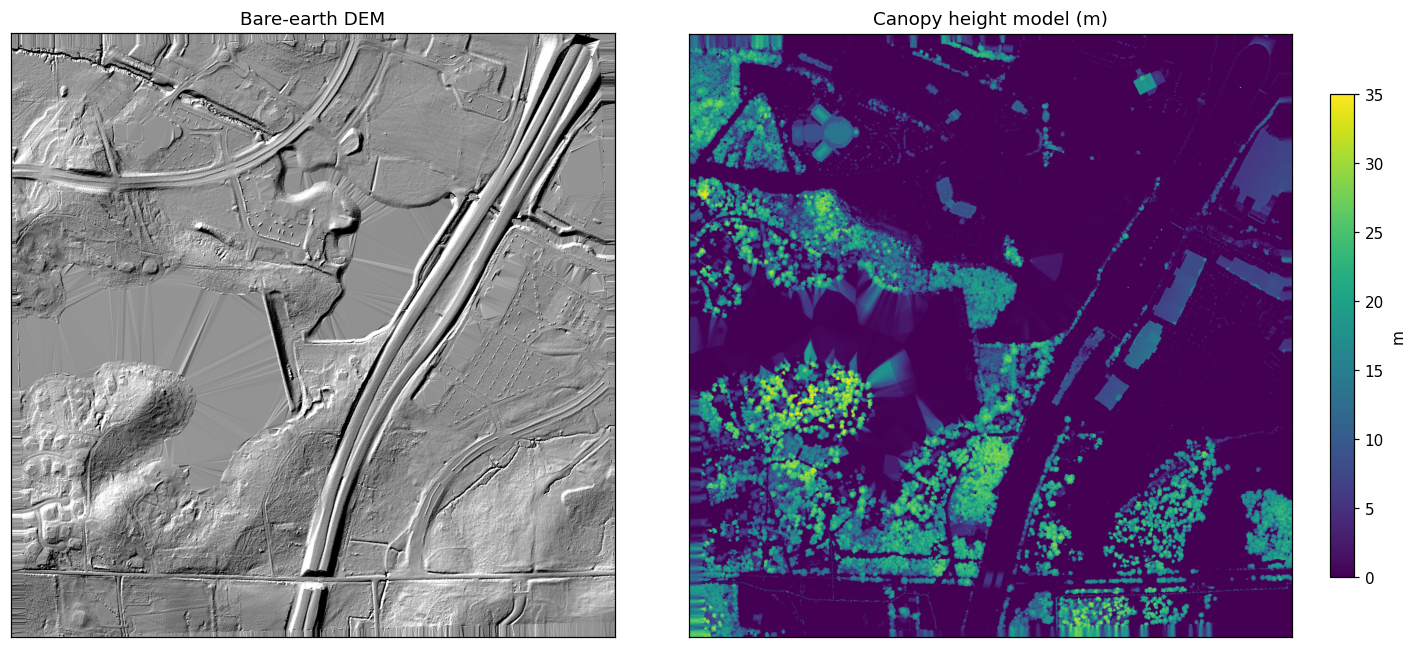

Canopy cover (> 5 m): 29%


In [4]:
smrf = rs.lidar.smrf(pc, cell=1.0, slope=0.15, window=18)
valid = np.isin(pc["classification"], [2, 3, 4])
agree = ((smrf["classification"] == 2) == (pc["classification"] == 2))[valid].mean()
print(f"SMRF vs provider ground labels: {agree:.1%} agreement")
dem = rs.lidar.dem(pc, 1.0)
chm = rs.lidar.chm(rs.lidar.dsm(pc, 1.0, bounds=pc.bbox), dem)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
rs.viz.plot_raster(rs.lidar.hillshade(dem), ax=axes[0], cmap="gray", colorbar=False, title="Bare-earth DEM")
rs.viz.plot_raster(chm, ax=axes[1], cmap="viridis", vmax=35, title="Canopy height model (m)")
for a in axes: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
print(f"Canopy cover (> 5 m): {float((chm > 5).mean()):.0%}")

## Individual-tree inventory


14,876 trees ≥ 5 m; 61 trees/ha (23 implausibly large segments removed as merged crowns)


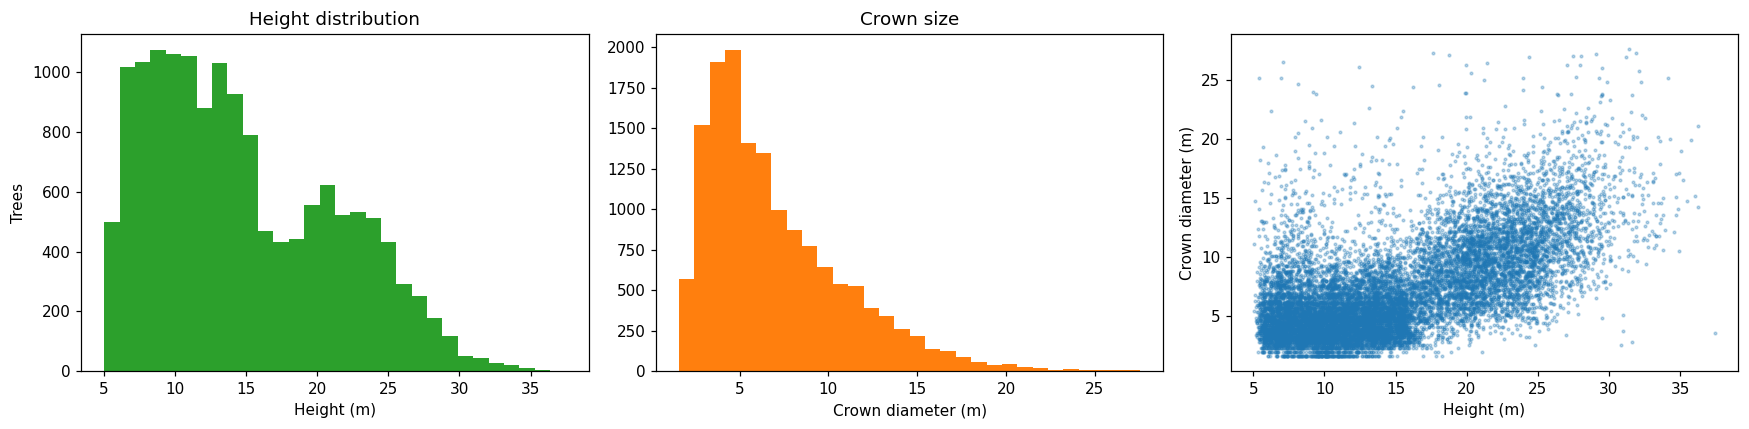

,height,diameter_m,area_m2
mean,14.8,7.0,50.8
50%,13.5,6.0,28.0
max,37.5,27.5,596.0


In [5]:
tops = rs.lidar.detect_trees(chm, min_height=5)
labels, crowns = rs.lidar.segment_crowns(chm, tops, min_height=3)
n_all = len(crowns)
merged = crowns.area_m2 > 600                     # > ~28 m crown diameter: merged crowns or non-tree objects
crowns = crowns[(crowns.area_m2 >= 2) & (crowns.height >= 5) & ~merged].reset_index(drop=True)
print(f"{len(crowns):,} trees ≥ 5 m; {len(crowns) / area_ha:.0f} trees/ha "
      f"({int(merged.sum())} implausibly large segments removed as merged crowns)")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(crowns.height, bins=30, color="C2"); axes[0].set(xlabel="Height (m)", ylabel="Trees", title="Height distribution")
axes[1].hist(crowns.diameter_m, bins=30, color="C1"); axes[1].set(xlabel="Crown diameter (m)", title="Crown size")
axes[2].scatter(crowns.height, crowns.diameter_m, s=3, alpha=0.3); axes[2].set(xlabel="Height (m)", ylabel="Crown diameter (m)")
plt.tight_layout(); plt.show()
crowns[["height", "diameter_m", "area_m2"]].describe().loc[["mean", "50%", "max"]].round(1)

## Tree biomass and carbon

Jucker et al. (2017) relate above-ground biomass to the product of tree height H and crown diameter
CD, without needing stem diameter: for angiosperms AGB (kg) = 0.016 · (H · CD)^2.013 · exp(0.204²/2).
Carbon is taken as 47 % of dry biomass (IPCC default).


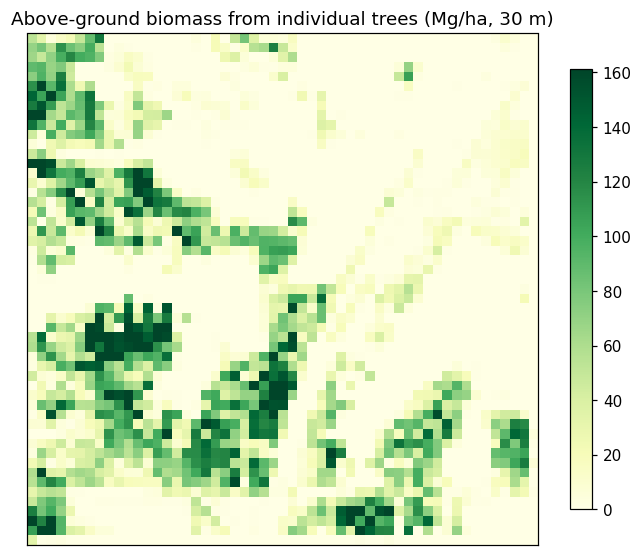

Total AGB 7,122 Mg; carbon 3,347 Mg C (≈ 12,273 Mg CO₂e); mean AGB in forested cells 69 Mg/ha


In [6]:
crowns["agb_kg"] = 0.016 * (crowns.height * crowns.diameter_m) ** 2.013 * np.exp(0.204 ** 2 / 2)
crowns["carbon_kg"] = 0.47 * crowns.agb_kg
cent = crowns.geometry.centroid
cell = 30.0
x0, y1 = pc.bbox[0], pc.bbox[3]
crowns["col"] = ((cent.x - x0) // cell).astype(int); crowns["row"] = ((y1 - cent.y) // cell).astype(int)
H = int(np.ceil((pc.bbox[3] - pc.bbox[1]) / cell)); W = int(np.ceil((pc.bbox[2] - pc.bbox[0]) / cell))
grid = np.zeros((H, W))
np.add.at(grid, (crowns.row.clip(0, H - 1), crowns.col.clip(0, W - 1)), crowns.agb_kg)
agb_ha = xr.DataArray(grid / 1000 / (cell * cell / 1e4), dims=("y", "x"),
                      coords={"y": y1 - cell * (np.arange(H) + 0.5), "x": x0 + cell * (np.arange(W) + 0.5)},
                      name="AGB (Mg/ha)").rio.write_crs(utm)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
rs.viz.plot_raster(agb_ha, ax=ax, cmap="YlGn", title="Above-ground biomass from individual trees (Mg/ha, 30 m)")
ax.set_xticks([]); ax.set_yticks([]); plt.show()
forest_cells = agb_ha > 10
print(f"Total AGB {crowns.agb_kg.sum() / 1000:,.0f} Mg; carbon {crowns.carbon_kg.sum() / 1000:,.0f} Mg C "
      f"(≈ {crowns.carbon_kg.sum() / 1000 * 44 / 12:,.0f} Mg CO₂e); mean AGB in forested cells "
      f"{float(agb_ha.where(forest_cells).mean()):.0f} Mg/ha")

## Area-based biomass model with prediction intervals

Inventories usually predict biomass per cell from area-based lidar metrics, which is faster and
less sensitive to segmentation errors. We use 30 m cells, close to typical field-plot size, so that
trees straddling cell edges matter less. We model the tree-based AGB from height percentiles, cover
and density, validate with spatial CV, and wrap the model in split-conformal prediction to obtain
90 % prediction intervals per cell.


Spatial-CV R² of the area-based model: 0.72 ± 0.04


90 % interval half-width ±42 Mg/ha; empirical coverage 97.3%


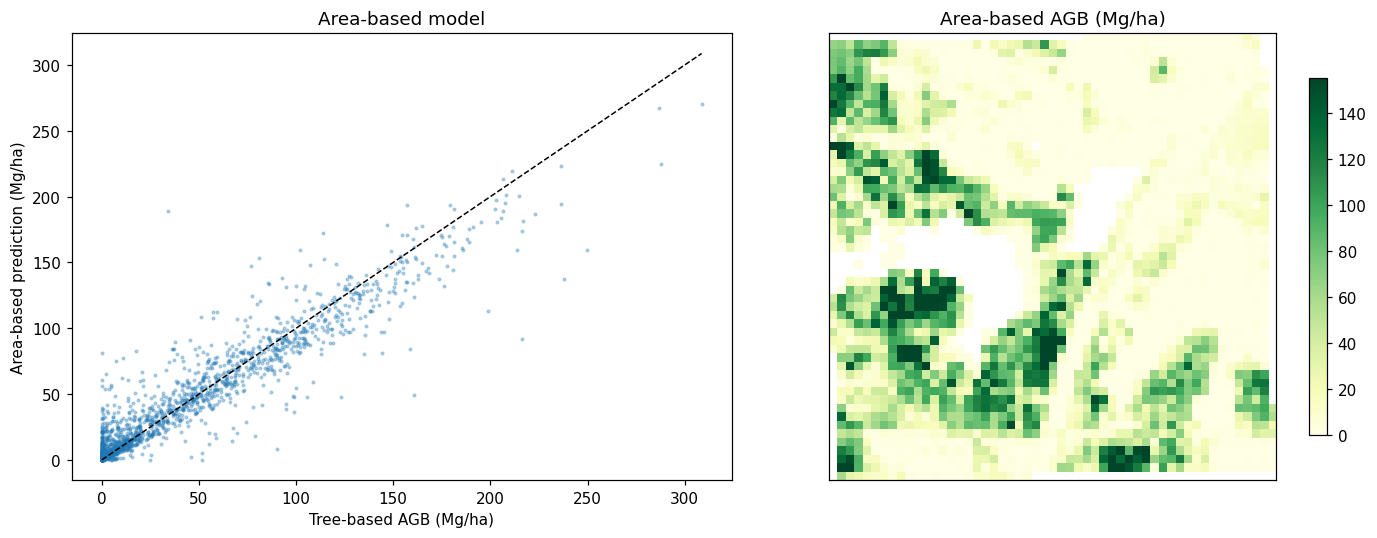

In [7]:
pcn = rs.lidar.normalize_heights(pc, dem)
met = rs.lidar.grid_metrics(pcn, res=cell, metrics=("hmax", "p95", "p75", "p50", "hstd", "cover", "density"))
met = xr.Dataset({k: v.rio.write_crs(utm).rio.reproject_match(agb_ha) for k, v in met.items()})
# merge on coordinates (never rely on array order: to_dataframe sorts y ascending)
X = xr.merge([met, agb_ha.rename("agb")]).to_dataframe().drop(columns="spatial_ref", errors="ignore").reset_index().dropna()
feats = ["hmax", "p95", "p75", "p50", "hstd", "cover", "density"]
Xf = X[feats].copy(); Xf.attrs["coords"] = X[["x", "y"]].to_numpy()
cv = rs.xai.cross_validate_spatial(rs.classify.Classifier("rf", task="regression", n_estimators=300, random_state=0),
                                   Xf, X.agb.values, rs.xai.SpatialBlockCV(5, 300, seed=0))
print(f"Spatial-CV R² of the area-based model: {cv['mean']:.2f} ± {cv['std']:.2f}")
cr = rs.xai.ConformalRegressor(rs.classify.Classifier("rf", task="regression", n_estimators=300, random_state=0),
                               alpha=0.1).fit(Xf, X.agb.values)
iv = cr.predict_interval(Xf)
cov = rs.xai.coverage(X.agb.values, iv.lower, iv.upper)
print(f"90 % interval half-width ±{cr.q_:.0f} Mg/ha; empirical coverage {cov:.1%}")
pred = X.assign(pred=iv.pred.values).set_index(["y", "x"])["pred"].to_xarray().reindex_like(agb_ha)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X.agb, iv.pred, s=3, alpha=0.3); axes[0].plot([0, X.agb.max()], [0, X.agb.max()], "k--", lw=1)
axes[0].set(xlabel="Tree-based AGB (Mg/ha)", ylabel="Area-based prediction (Mg/ha)", title="Area-based model")
rs.viz.plot_raster(pred, ax=axes[1], cmap="YlGn", title="Area-based AGB (Mg/ha)")
axes[1].set_xticks([]); axes[1].set_yticks([])
plt.tight_layout(); plt.show()

## Inventory report


In [8]:
tot = crowns.agb_kg.sum() / 1000
report = {
    "Area": f"{area_ha:.0f} ha (canopy cover > 5 m: {float((chm > 5).mean()):.0%})",
    "Trees ≥ 5 m": f"{len(crowns):,} ({len(crowns) / area_ha:.0f}/ha); median height {crowns.height.median():.1f} m",
    "Above-ground biomass": f"{tot:,.0f} Mg ({tot / area_ha:.0f} Mg/ha landscape mean)",
    "Carbon": f"{0.47 * tot:,.0f} Mg C ≈ {0.47 * tot * 44 / 12:,.0f} Mg CO₂e",
    "Area-based model (spatial CV R²)": f"{cv['mean']:.2f}",
    "Per-cell 90 % prediction interval": f"±{cr.q_:.0f} Mg/ha (coverage {cov:.0%})",
    "Main uncertainty": "Allometry (no field plots); crown segmentation merges/splits in dense stands",
}
pd.Series(report).to_frame("value")

,value
Area,244 ha (canopy cover > 5 m: 29%)
Trees ≥ 5 m,"14,876 (61/ha); median height 13.5 m"
Above-ground biomass,"7,122 Mg (29 Mg/ha landscape mean)"
Carbon,"3,347 Mg C ≈ 12,273 Mg CO₂e"
Area-based model (spatial CV R²),0.72
Per-cell 90 % prediction interval,±42 Mg/ha (coverage 97%)
Main uncertainty,Allometry (no field plots); crown segmentation...


**Extensions:** calibrate with field plots (replace the allometry); add GEDI L4A footprints to extend
beyond the lidar extent (Module 21); repeat with a later lidar survey to estimate growth and
removals (biomass change).
